# Lý thuyết về DFT và iDFT

---

# 1️⃣ Bối cảnh

Ta xét một tín hiệu rời rạc hữu hạn:

$$
x[n], \quad n = 0,1,2,\dots,N-1
$$

DFT được xây dựng trên giả định:

$$
x[n+N] = x[n]
$$

Tức là tín hiệu được xem như **tuần hoàn chu kỳ N**.

---

# 2️⃣ Định nghĩa DFT

Biến đổi Fourier rời rạc (Discrete Fourier Transform – DFT) được định nghĩa:

$$
X[k] =
\sum_{n=0}^{N-1}
x[n] \; e^{-i2\pi kn/N}
\quad
,\quad
k = 0,1,\dots,N-1
$$

Trong đó:

- $x[n]$ : tín hiệu trong miền thời gian (rời rạc)
- $X[k]$ : phổ trong miền tần số rời rạc
- $N$ : số mẫu
- $k$ : chỉ số tần số

---

# 3️⃣ Ý nghĩa

DFT thực hiện phép chiếu tín hiệu $x[n]$ lên các cơ sở:

$$
e^{-i2\pi kn/N}
$$

Các hàm mũ phức này tạo thành một **hệ trực giao rời rạc** trên không gian chiều $N$.

DFT thực chất là một phép đổi cơ sở tuyến tính.

---

# 4️⃣ iDFT (Inverse DFT)

Nghịch đảo DFT được định nghĩa:

$$
x[n]
=
\frac{1}{N}
\sum_{k=0}^{N-1}
X[k] \; e^{i2\pi kn/N}
\quad
,\quad
n = 0,1,\dots,N-1
$$

---

# 5️⃣ Tính trực giao quan trọng

Cơ sở mũ phức thỏa mãn:

$$
\sum_{n=0}^{N-1}
e^{i2\pi (k-m)n/N}
=
\begin{cases}
N, & k = m \\
0, & k \neq m
\end{cases}
$$

Tính chất này đảm bảo:

- DFT và iDFT là nghịch đảo chính xác của nhau
- Không mất thông tin

---

# 6️⃣ DFT dưới dạng ma trận

Ta có thể viết:

$$
X = W x
$$

với ma trận DFT:

$$
W_{k,n} = e^{-i2\pi kn/N}
$$

iDFT tương ứng:

$$
x = \frac{1}{N} W^H X
$$

Trong đó $W^H$ là chuyển vị liên hợp (Hermitian).

---

# 7️⃣ Đặc điểm của DFT

## 🔹 Rời rạc

- Miền thời gian rời rạc
- Miền tần số cũng rời rạc

## 🔹 Tuần hoàn

Cả hai miền đều tuần hoàn chu kỳ N:

$$
X[k+N] = X[k]
$$

---

# 8️⃣ Mối liên hệ với DTFT

DTFT:

$$
X(v)=\sum_{n=-\infty}^{\infty} x[n] e^{-i2\pi v nT_s}
$$

DFT là việc:

- Lấy hữu hạn N mẫu của $x[n]$
- Lấy mẫu phổ DTFT tại các điểm:

$$
v_k = \frac{k}{NT_s}
$$

Tức là:

$$
X[k] = X(v_k)
$$

---

# 9️⃣ Diễn giải hình học

Không gian $x[n]$ là một vector trong $\mathbb{C}^N$.

DFT:

- Phân tích vector này thành tổng các vector cơ sở mũ phức.
- Hệ số phân tích chính là $X[k]$.

iDFT:

- Tổng hợp lại từ các hệ số phổ.

---

# 🔟 Độ phức tạp

DFT trực tiếp:

$$
O(N^2)
$$

FFT (Fast Fourier Transform):

$$
O(N\log N)
$$

FFT chỉ là thuật toán nhanh để tính DFT.

---

# 1️⃣1️⃣ Tóm tắt

DFT:

$$
X[k] =
\sum_{n=0}^{N-1}
x[n] e^{-i2\pi kn/N}
$$

iDFT:

$$
x[n]
=
\frac{1}{N}
\sum_{k=0}^{N-1}
X[k] e^{i2\pi kn/N}
$$

DFT là phép đổi cơ sở tuyến tính giữa:

- Miền thời gian rời rạc hữu hạn
- Miền tần số rời rạc tuần hoàn

Nó không phải gần đúng – mà là một phép biến đổi chính xác và khả nghịch.


Max reconstruction error: 2.717e-14


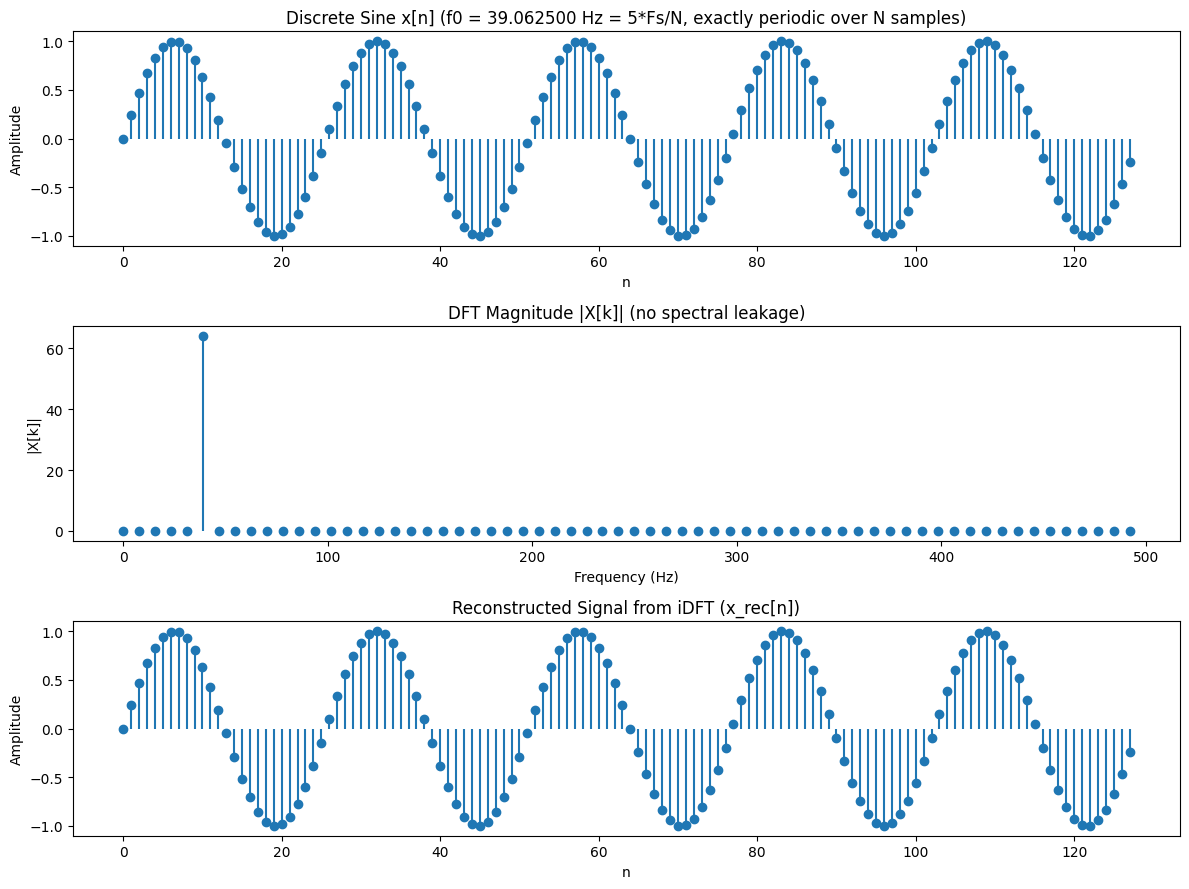

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1) DFT / iDFT (không FFT)
# =========================
def dft(x):
    x = np.asarray(x, dtype=complex)
    N = x.size
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        s = 0j
        for n in range(N):
            s += x[n] * np.exp(-2j * np.pi * k * n / N)
        X[k] = s
    return X

def idft(X):
    X = np.asarray(X, dtype=complex)
    N = X.size
    x = np.zeros(N, dtype=complex)
    for n in range(N):
        s = 0j
        for k in range(N):
            s += X[k] * np.exp(2j * np.pi * k * n / N)
        x[n] = s / N
    return x

# =========================
# 2) Chọn sóng sin "crop" đúng tuần hoàn cho DFT
#    f0 = (k0/N) * Fs  -> đúng 1 bin, không leakage
# =========================
Fs = 1000     # Hz
N  = 128
k0 = 5
f0 = k0 * Fs / N

n = np.arange(N)
x = np.sin(2*np.pi*f0*n/Fs)  # x[n] rời rạc

# =========================
# 3) DFT và iDFT
# =========================
X = dft(x)
x_rec = idft(X).real  # lấy phần thực (do sai số số học rất nhỏ)

# Sai số tái tạo
err = np.max(np.abs(x - x_rec))
print(f"Max reconstruction error: {err:.3e}")

# Trục tần số (Hz)
freq = np.arange(N) * Fs / N

# =========================
# 4) Visualization (rời rạc)
# =========================
plt.figure(figsize=(12, 9))

# (a) Tín hiệu gốc x[n]
plt.subplot(3, 1, 1)
plt.stem(n, x, basefmt=" ")
plt.title(f"Discrete Sine x[n] (f0 = {f0:.6f} Hz = {k0}*Fs/N, exactly periodic over N samples)")
plt.xlabel("n")
plt.ylabel("Amplitude")

# (b) Phổ biên độ |X[k]| (chỉ nửa phổ)
plt.subplot(3, 1, 2)
plt.stem(freq[:N//2], np.abs(X[:N//2]), basefmt=" ")
plt.title("DFT Magnitude |X[k]| (no spectral leakage)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|X[k]|")

# (c) Tín hiệu tái tạo từ iDFT
plt.subplot(3, 1, 3)
plt.stem(n, x_rec, basefmt=" ")
plt.title("Reconstructed Signal from iDFT (x_rec[n])")
plt.xlabel("n")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

# Lý thuyết về FFT và iFFT

---

# 1️⃣ FFT là gì?

FFT (Fast Fourier Transform) không phải là một phép biến đổi mới.

Nó là **thuật toán nhanh để tính DFT**.

DFT được định nghĩa:

$$
X[k] =
\sum_{n=0}^{N-1}
x[n] e^{-i2\pi kn/N}
$$

Độ phức tạp của DFT trực tiếp:

$$
O(N^2)
$$

FFT làm giảm xuống:

$$
O(N \log N)
$$

---

# 2️⃣ Ý tưởng cốt lõi của FFT

Giả sử $N$ là số chẵn.

Ta tách tổng DFT thành:

- Các mẫu chẵn
- Các mẫu lẻ

Viết lại:

$$
X[k]
=
\sum_{n=0}^{N/2-1}
x[2n] e^{-i2\pi k(2n)/N}
+
\sum_{n=0}^{N/2-1}
x[2n+1] e^{-i2\pi k(2n+1)/N}
$$

Rút gọn:

$$
X[k]
=
\sum_{n=0}^{N/2-1}
x[2n] e^{-i2\pi kn/(N/2)}
+
e^{-i2\pi k/N}
\sum_{n=0}^{N/2-1}
x[2n+1] e^{-i2\pi kn/(N/2)}
$$

Ta thấy:

- Hai tổng con đều là DFT kích thước N/2

---

# 3️⃣ Dạng tổng quát của FFT

Gọi:

$$
E[k] = DFT\{x[2n]\}
$$

$$
O[k] = DFT\{x[2n+1]\}
$$

Khi đó:

$$
X[k] = E[k] + W_N^k O[k]
$$

$$
X[k+N/2] = E[k] - W_N^k O[k]
$$

Trong đó:

$$
W_N^k = e^{-i2\pi k/N}
$$

Thuật toán này gọi là:

## Cooley–Tukey FFT

---

# 4️⃣ Vì sao nhanh?

Mỗi bước:

- Chia N thành 2 bài toán N/2
- Số mức đệ quy: $\log_2 N$
- Mỗi mức cần N phép toán

Tổng:

$$
O(N \log N)
$$

---

# 5️⃣ iFFT là gì?

iFFT là thuật toán nhanh để tính iDFT.

iDFT được định nghĩa:

$$
x[n]
=
\frac{1}{N}
\sum_{k=0}^{N-1}
X[k] e^{i2\pi kn/N}
$$

So với DFT:

- Dấu mũ đổi chiều
- Chia thêm 1/N

---

# 6️⃣ Quan hệ giữa FFT và iFFT

iFFT có thể tính bằng:

1. Lấy liên hợp phức của phổ
2. Tính FFT
3. Lấy liên hợp lại
4. Chia cho N

Vì:

$$
iDFT(X)
=
\frac{1}{N}
\overline{DFT(\overline{X})}
$$

---

# 7️⃣ Bản chất toán học

DFT là phép nhân ma trận:

$$
X = W x
$$

FFT chỉ là:

- Tái cấu trúc phép nhân ma trận đó
- Tận dụng tính chất lặp của các mũ phức

Không thay đổi kết quả.

---

# 8️⃣ Điều kiện thường gặp

FFT chuẩn hoạt động tối ưu khi:

$$
N = 2^m
$$

Nhưng vẫn có FFT cho N bất kỳ (mixed radix, Bluestein, v.v.).

---

# 9️⃣ Tóm tắt

DFT:

$$
X[k] =
\sum_{n=0}^{N-1}
x[n] e^{-i2\pi kn/N}
$$

iDFT:

$$
x[n]
=
\frac{1}{N}
\sum_{k=0}^{N-1}
X[k] e^{i2\pi kn/N}
$$

FFT:

- Thuật toán nhanh tính DFT
- Độ phức tạp $O(N\log N)$

iFFT:

- Thuật toán nhanh tính iDFT
- Dựa trên cấu trúc tương tự FFT

---

# 🔥 Kết luận quan trọng

FFT không thay đổi lý thuyết Fourier.

Nó chỉ làm cho việc tính toán trở nên khả thi trong thực tế.

Nếu không có FFT:

- Xử lý tín hiệu số
- Xử lý ảnh
- OFDM
- Phổ học
- Radar

sẽ không thể thực hiện ở quy mô lớn.


Max reconstruction error: 5.551e-16


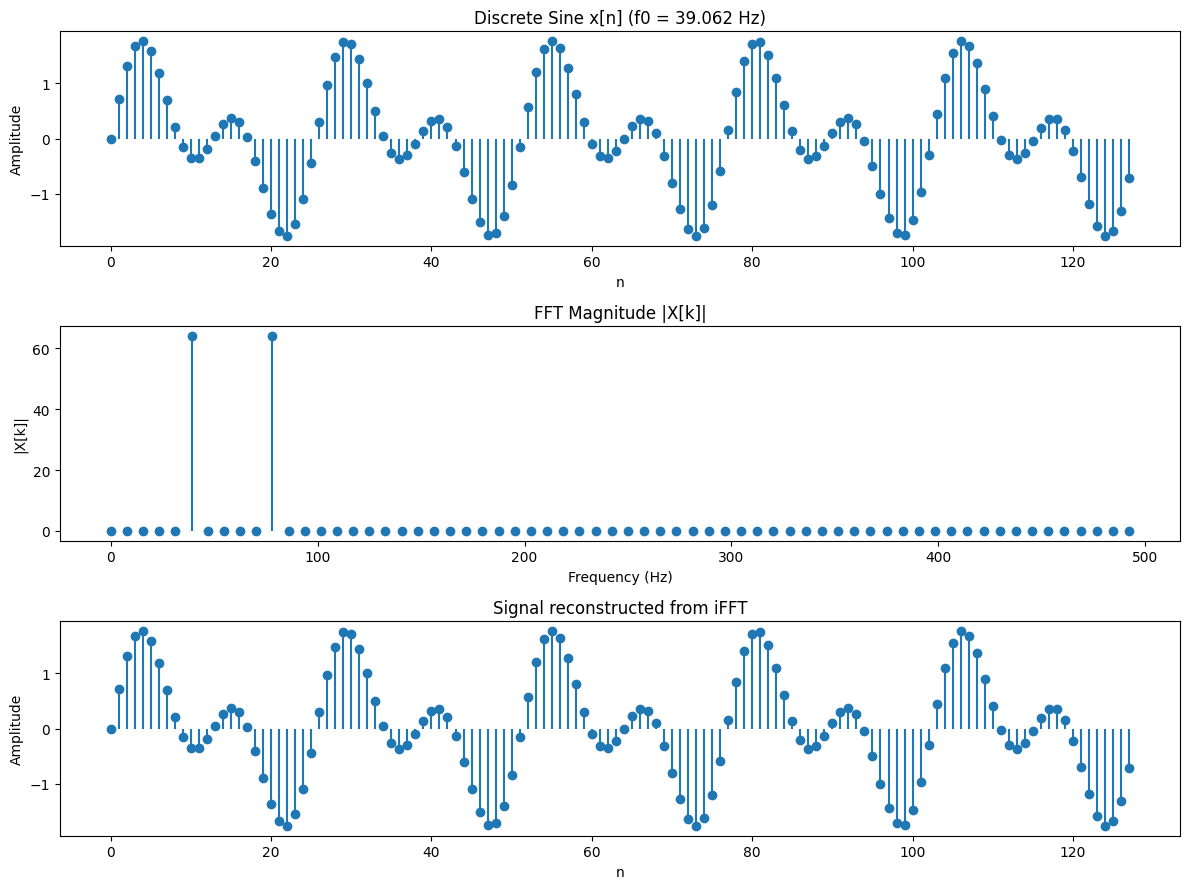

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1) Tạo tín hiệu rời rạc
# =========================
Fs = 1000     # Sampling frequency (Hz)
N  = 128      # Number of samples
k0 = 5        # Chọn đúng bin

f0 = k0 * Fs / N

n = np.arange(N)
x = np.sin(2*np.pi*f0*n/Fs) +  np.sin(2*np.pi*(f0+f0)*n/Fs) 

# =========================
# 2) FFT và iFFT
# =========================
X_fft = np.fft.fft(x)
x_rec = np.fft.ifft(X_fft)

# Sai số tái tạo
error = np.max(np.abs(x - x_rec.real))
print(f"Max reconstruction error: {error:.3e}")

# Frequency axis
freq = np.arange(N) * Fs / N

# =========================
# 3) Visualization
# =========================
plt.figure(figsize=(12,9))

# ---- Time domain (original) ----
plt.subplot(3,1,1)
plt.stem(n, x, basefmt=" ")
plt.title(f"Discrete Sine x[n] (f0 = {f0:.3f} Hz)")
plt.xlabel("n")
plt.ylabel("Amplitude")

# ---- Frequency domain ----
plt.subplot(3,1,2)
plt.stem(freq[:N//2], np.abs(X_fft[:N//2]), basefmt=" ")
plt.title("FFT Magnitude |X[k]|")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|X[k]|")

# ---- Reconstructed signal ----
plt.subplot(3,1,3)
plt.stem(n, x_rec.real, basefmt=" ")
plt.title("Signal reconstructed from iFFT")
plt.xlabel("n")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()